In [108]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.metrics import mean_absolute_error 
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from scipy.special import expit
from scipy.special import softmax
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor

In [109]:
df = pd.read_csv('data/picher_stats_2017.csv')
df.head(3)

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
1,소사,LG,11,11,1,0,0,30,29,185.1,...,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000
2,양현종,KIA,20,6,0,0,0,31,31,193.1,...,0.79,0.332,72.1,3.44,6.54,3.94,3.82,5.64,230000,150000


In [110]:
df.columns

Index(['선수명', '팀명', '승', '패', '세', '홀드', '블론', '경기', '선발', '이닝', '삼진/9',
       '볼넷/9', '홈런/9', 'BABIP', 'LOB%', 'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR',
       '연봉(2018)', '연봉(2017)'],
      dtype='str')

In [111]:
label = df['연봉(2018)']
team = df['팀명']
data = df[df.columns[2:-2]]
#data = df[df.columns.difference[('선수명','팀명','연봉(2018)')]
data.head(2)

,승,패,세,홀드,블론,경기,선발,이닝,삼진/9,볼넷/9,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR
0,16,7,0,0,0,30,30,190.0,8.95,2.13,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62
1,11,11,1,0,0,30,29,185.1,7.43,1.85,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08


In [112]:
# team = team.to_numpy().reshape(-1,1)
# # 원핫인코딩 객체 생성 / NumPy 배열로 반환 / 0 부분 1개 삭제, True,False가 아닌 1,0
# encoder = OneHotEncoder(sparse_output=False,drop='first', dtype=int)
# # 원핫인코딩 적용
# result = encoder.fit_transform(team)
# # 숫자 데이터 + 원핫인코딩 결합
# total_data = np.concatenate((data, result), axis=1)
# total_data

In [113]:
train_data,test_data,train_label,test_label = train_test_split(data,label,test_size=0.2,random_state=42)

In [114]:
lr = LinearRegression()
lr.fit(train_data, train_label)
predict = lr.predict(test_data)

print(f'학습 정확도: {lr.score(train_data, train_label)*100}%')
print(f'테스트 정확도: {lr.score(test_data, test_label)*100}%')

학습 정확도: 70.83700904860383%
테스트 정확도: 43.89706288990241%


In [115]:
poly = PolynomialFeatures(degree=2, include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
# poly.get_feature_names_out()

In [116]:
lr2 = LinearRegression()
lr2.fit(train_poly, train_label)
predict2 = lr2.predict(test_poly)

print(f'학습 정확도: {lr2.score(train_poly, train_label)*100}%')
print(f'테스트 정확도: {lr2.score(test_poly, test_label)*100}%')

학습 정확도: 100.0%
테스트 정확도: -2011.0997573736472%


In [117]:
# 정규화
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [118]:
# # 규제 알고리즘
# ridge = Ridge()
# ridge.fit(train_scaled, train_label)
# score5 = ridge.score(train_scaled, train_label)
# score6 = ridge.score(test_scaled, test_label)
# print(f'정확도:{score5*100}%, {score6*100}%')

In [119]:
# # 1. input1은 이미 리스트이므로 그대로 사용
# # input1 = [14,9,0,0,0,29,29,180.1,6.24,2.55,0.6,0.293,75.8,3.14,7.28,4.26,4.35,3.85]
# input1 = [9,8,0,2,0,35,24,137.1,9.11,4.19,0.52,0.321,73.1,3.67,4.99,3.91,3.67,3.78]

# # 2. scikit-learn 입력 규격(2차원 배열, 샘플 1개)에 맞게 변환
# input_data = np.array(input1).reshape(1, -1)

# # 3. 다항식 특성 변환 및 스케일링 적용
# input_poly = poly.transform(input_data)
# input_scaled = ss.transform(input_poly)

# # 4. 예측 수행
# ipredict = ridge.predict(input_scaled)
# print('연봉 예측: ', ipredict[0])

In [120]:
# 3. GridSearchCV로 Ridge의 최적 alpha 찾기
params = {'alpha': [0.1, 1, 10, 100, 1000, 10000]}
gs = GridSearchCV(Ridge(), params, cv=5, scoring='r2', n_jobs=-1)
gs.fit(train_scaled, train_label)

best_ridge = gs.best_estimator_
print(f"최적 alpha: {gs.best_params_}")
print(f'학습 정확도(R^2): {best_ridge.score(train_scaled, train_label)*100:.2f}%')
print(f'테스트 정확도(R^2): {best_ridge.score(test_scaled, test_label)*100:.2f}%')

# 4. 단일 데이터 예측
input1 = [9,8,0,2,0,35,24,137.1,9.11,4.19,0.52,0.321,73.1,3.67,4.99,3.91,3.67,3.78]
input_data = np.array(input1).reshape(1, -1)
input_poly = poly.transform(input_data)
input_scaled = ss.transform(input_poly)

ipredict = best_ridge.predict(input_scaled)
print('연봉 예측: ', ipredict[0])

최적 alpha: {'alpha': 100}
학습 정확도(R^2): 83.11%
테스트 정확도(R^2): 64.28%
연봉 예측:  42968.71642293488


c:\Python31315\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


In [121]:
# pip install statsmodels
# 회귀분석 통계결과표 : P>|t| 통계량의 절대값보다 크거나 같은 값이 나올 확률
import statsmodels.api as sm

train_scaled = sm.add_constant(train_scaled)
model = sm.OLS(train_label,train_scaled).fit()
# model.summary()

C:\Users\user\AppData\Local\Temp\ipykernel_2024\3792915334.py:6: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(train_label,train_scaled).fit()


[Text(0, 0, 'const'),
 Text(1, 0, 'x1'),
 Text(2, 0, 'x2'),
 Text(3, 0, 'x3'),
 Text(4, 0, 'x4'),
 Text(5, 0, 'x5'),
 Text(6, 0, 'x6'),
 Text(7, 0, 'x7'),
 Text(8, 0, 'x8'),
 Text(9, 0, 'x9'),
 Text(10, 0, 'x10'),
 Text(11, 0, 'x11'),
 Text(12, 0, 'x12'),
 Text(13, 0, 'x13'),
 Text(14, 0, 'x14'),
 Text(15, 0, 'x15'),
 Text(16, 0, 'x16'),
 Text(17, 0, 'x17'),
 Text(18, 0, 'x18'),
 Text(19, 0, 'x19'),
 Text(20, 0, 'x20'),
 Text(21, 0, 'x21'),
 Text(22, 0, 'x22'),
 Text(23, 0, 'x23'),
 Text(24, 0, 'x24'),
 Text(25, 0, 'x25'),
 Text(26, 0, 'x26'),
 Text(27, 0, 'x27'),
 Text(28, 0, 'x28'),
 Text(29, 0, 'x29'),
 Text(30, 0, 'x30'),
 Text(31, 0, 'x31'),
 Text(32, 0, 'x32'),
 Text(33, 0, 'x33'),
 Text(34, 0, 'x34'),
 Text(35, 0, 'x35'),
 Text(36, 0, 'x36'),
 Text(37, 0, 'x37'),
 Text(38, 0, 'x38'),
 Text(39, 0, 'x39'),
 Text(40, 0, 'x40'),
 Text(41, 0, 'x41'),
 Text(42, 0, 'x42'),
 Text(43, 0, 'x43'),
 Text(44, 0, 'x44'),
 Text(45, 0, 'x45'),
 Text(46, 0, 'x46'),
 Text(47, 0, 'x47'),
 Text(48,

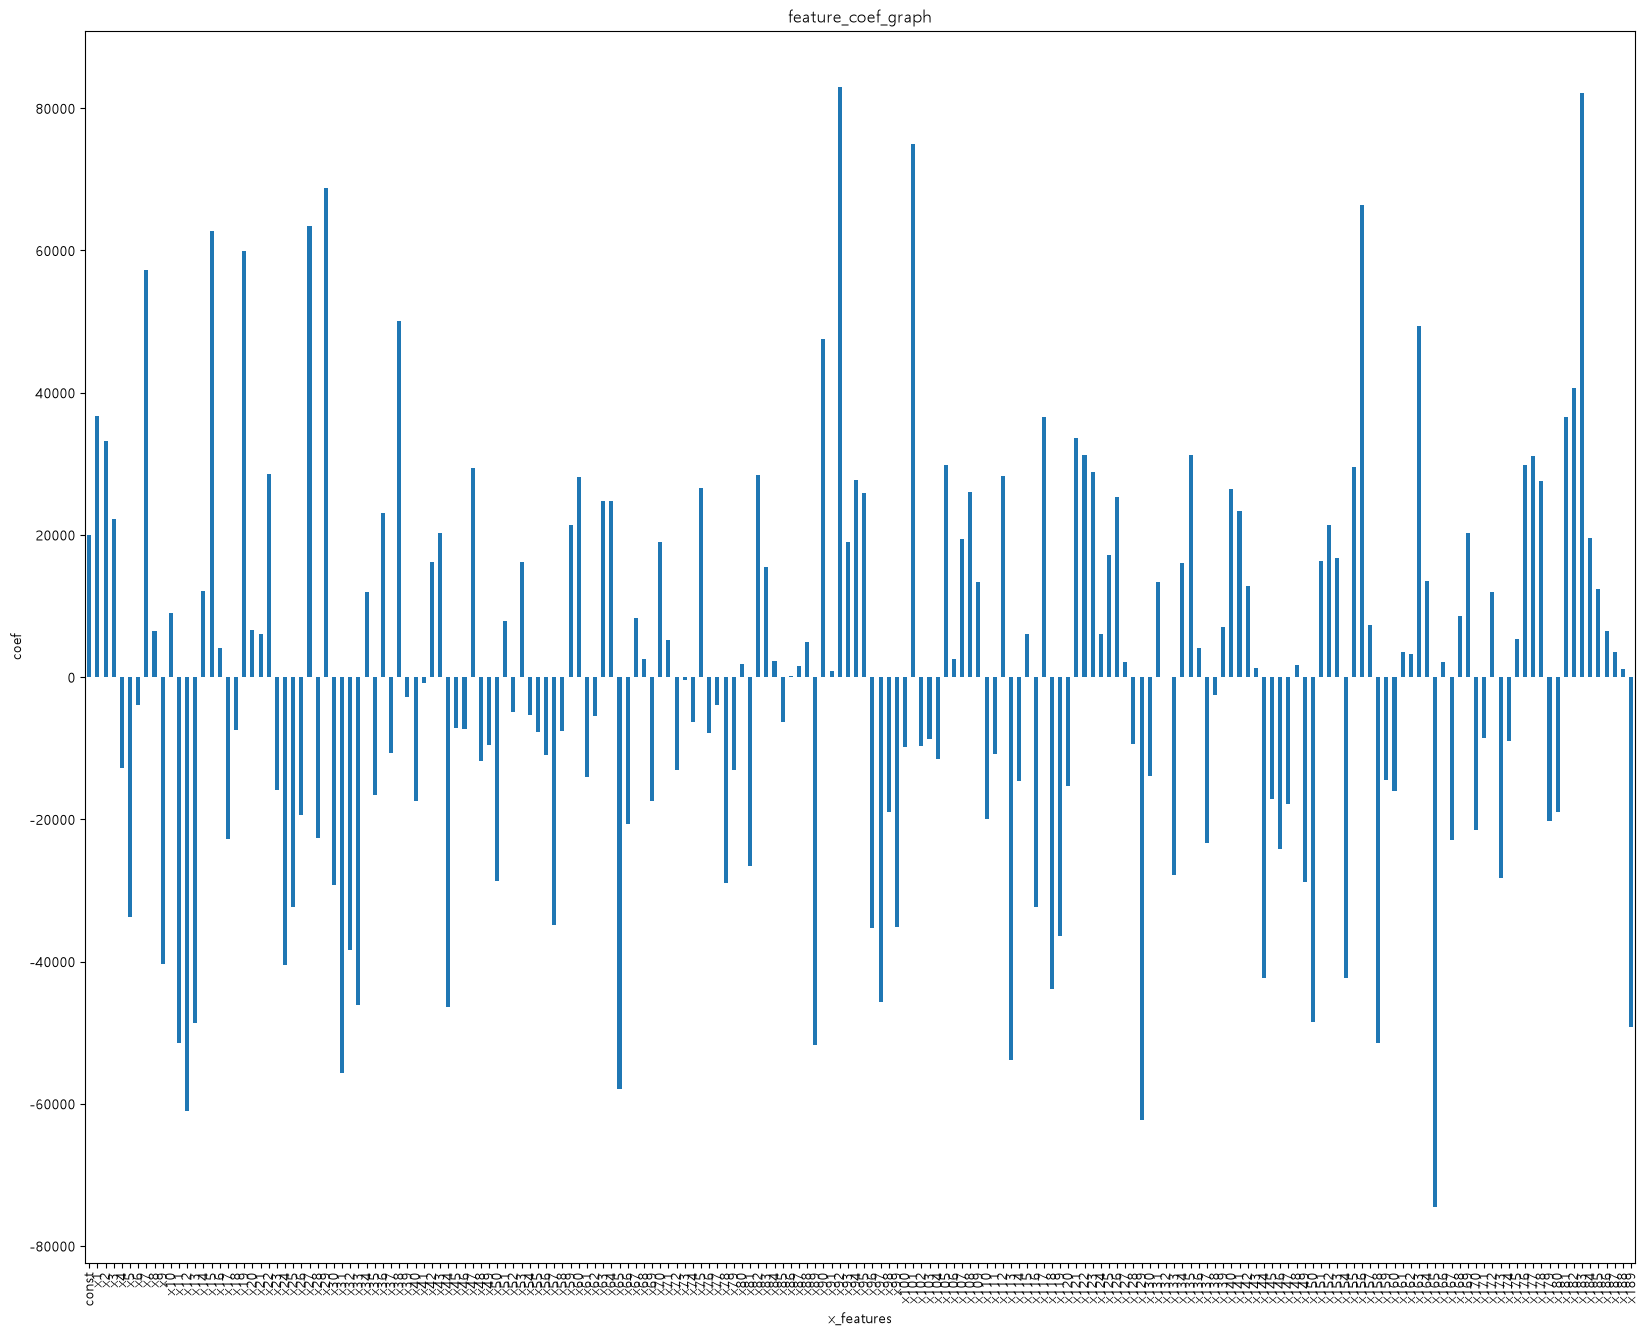

In [122]:
plt.rcParams['figure.figsize'] = [20, 16]

# 회귀 계수를 리스트로 반환합니다.
coefs = model.params.tolist()
coefs_series = pd.Series(coefs)

# 변수명을 리스트로 반환합니다.
x_labels = model.params.index.tolist()

# 회귀 계수를 출력합니다.
ax = coefs_series.plot(kind='bar')
ax.set_title('feature_coef_graph')
ax.set_xlabel('x_features')
ax.set_ylabel('coef')
ax.set_xticklabels(x_labels)

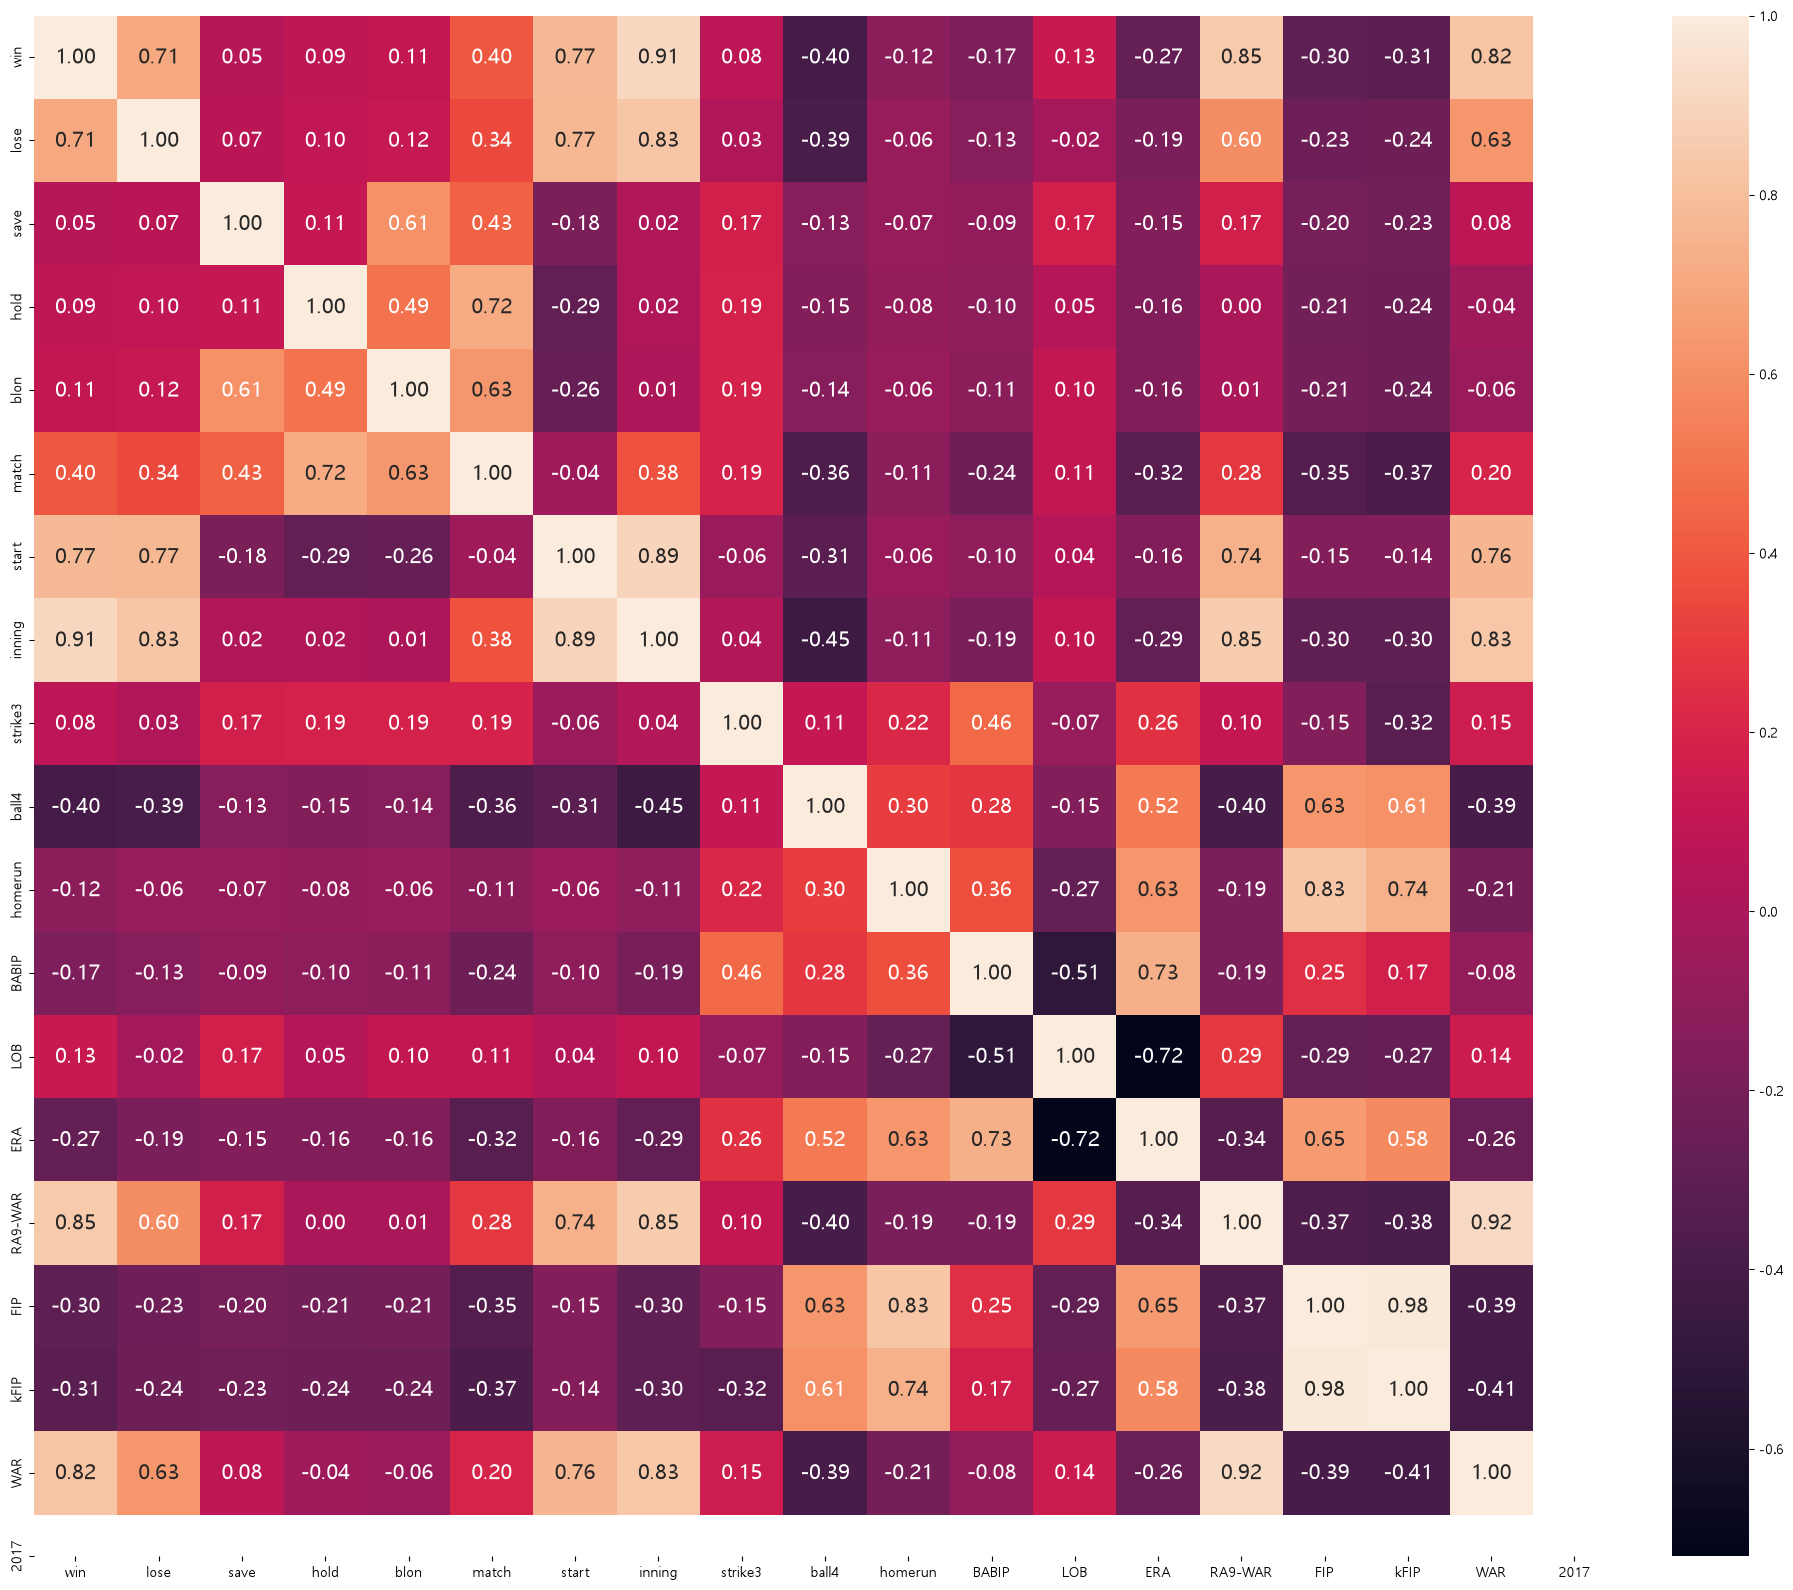

In [123]:
import seaborn as sns

# 피처간의 상관계수 행렬을 계산
corr = df[data.columns].corr(method='pearson')
show_cols = ['win', 'lose', 'save', 'hold', 'blon', 'match', 'start',
             'inning', 'strike3', 'ball4', 'homerun', 'BABIP', 'LOB',
             'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR', '2017']

# corr 행렬 히트맵을 시각화합니다.
# plt.rc('font', family='NanumGothicOTF')

hm = sns.heatmap(corr.values,
            cbar=True,
            annot=True,
            square=True,
            fmt='.2f',
            annot_kws={'size': 15},
            yticklabels=show_cols,
            xticklabels=show_cols)

plt.tight_layout()
plt.show()